**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
suppressMessages(suppressWarnings(library(lmtest)))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
## init: region folder
vec = c("fcc_astarr_macs_input_overlap", "fcc_astarr_macs_input_union")
names(vec) = vec

VEC_TXT_FOLDER = vec
for (txt in vec) {cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
vec = c("CRISPRi-HCRFF", "CRISPRi-Growth", "ENCODE-rE2G Benchmark", "CRISPR_Pool", "CRISPR_rmGrowth")
names(vec) = vec
VEC_TXT_ASSAY_OUT = vec

vec = c("ASTARR", "WSTARR", "LMPRA", "TMPRA") #, "ATAC")
names(vec) = vec
VEC_TXT_ASSAY_INP = vec

**Check input files**

In [4]:
txt_folder = "fcc_astarr_macs_input_union"
txt_fdiry  = file.path(FD_RES, "analysis_fcc_correlation", txt_folder)
txt_fname  = "*.rds"
txt_fglob  = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for (txt in vec) {cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/data.region.merge.group_crispr.score_starrmpra.rds 


## Import data

In [5]:
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "data.region.merge.group_crispr.score_starrmpra.rds"
txt_fpath = file.path(txt_fdiry, txt_fname)

lst = readRDS(txt_fpath)

lst_dat_region_merge = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$`0.01`
[1] 627553      7

$`0.02`
[1] 627553      7

$`0.03`
[1] 627553      7

$`0.04`
[1] 627553      7

$`0.05`
[1] 627553      7

$`0.06`
[1] 627553      7

$`0.07`
[1] 627553      7

$`0.08`
[1] 627553      7

$`0.09`
[1] 627553      7

$`0.10`
[1] 627553      7

$`0.20`
[1] 627553      7

$`0.30`
[1] 627553      7

$`0.40`
[1] 627553      7

$`0.50`
[1] 627553      7



CutOff_CRISPR,Region,Assay_CRISPR,Group_CRISPR,Score_CRISPR,Assay_STARRMPRA,Score_STARRMPRA
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,ASTARR,-1.2216566
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,ATAC,2.3214952
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,WSTARR,0.5896695


## Prepare data

**Choose a threshold and Use CRISPR pool**

In [6]:
lst = lst_dat_region_merge
dat = lst[["0.01"]]
dat = dat %>% dplyr::filter(Assay_CRISPR == "CRISPR_Pool")

dat_region_merge = dat
print(dim(dat))
print(table(dat$Assay_STARRMPRA))
fun_display_table(head(dat))

[1] 298268      7

ASTARR   ATAC  LMPRA  TMPRA WSTARR 
 81233  81233  54295   1053  80454 


CutOff_CRISPR,Region,Assay_CRISPR,Group_CRISPR,Score_CRISPR,Assay_STARRMPRA,Score_STARRMPRA
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,ASTARR,-1.2216566
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,ATAC,2.3214952
0.01,chr10:100009096-100010466,CRISPR_Pool,0,-0.0378617,WSTARR,0.5896695
0.01,chr10:100045961-100046653,CRISPR_Pool,0,0.1087357,ASTARR,-0.4754832
0.01,chr10:100045961-100046653,CRISPR_Pool,0,0.1087357,ATAC,0.0523481
0.01,chr10:100045961-100046653,CRISPR_Pool,0,0.1087357,LMPRA,-0.1956047


**Convert long to wide data**

In [7]:
dat = dat_region_merge
dat = dat %>% 
    dplyr::select(Region, Group_CRISPR, Assay_STARRMPRA, Score_STARRMPRA) %>%
    dplyr::mutate(Assay_STARRMPRA = paste0("Score_", Assay_STARRMPRA)) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(names_from = Assay_STARRMPRA, values_from = Score_STARRMPRA)

dat_region_wide = dat
print(dim(dat))
head(dat)

[1] 81233     7


Region,Group_CRISPR,Score_ASTARR,Score_ATAC,Score_WSTARR,Score_LMPRA,Score_TMPRA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr10:100009096-100010466,0,-1.2216566,2.32149525,0.5896695,NA,NA
chr10:100045961-100046653,0,-0.4754832,0.05234815,-0.7609183,-0.1956047,NA
chr10:100065094-100065486,0,0.6994377,0.06897297,1.8573949,-0.3629430,NA
chr10:100129051-100131059,0,1.0734693,-0.26698551,-0.3125192,-0.8607215,NA
chr10:100185017-100187275,0,1.0612349,2.40954724,0.7280645,-0.6414871,NA
chr10:100228452-100230090,0,1.0910395,1.50716462,0.9391139,2.2435099,NA


**Get a common intersection of regions for all STARR/MPRA**

In [8]:
dat = dat_region_wide
dat = dat %>% tidyr::drop_na()

dat_region_overlap = dat
print(dim(dat))
head(dat)

[1] 802   7


Region,Group_CRISPR,Score_ASTARR,Score_ATAC,Score_WSTARR,Score_LMPRA,Score_TMPRA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr11:32870601-32871324,0,-0.8538079,-0.2403204,-1.1918490,-1.176334223,-0.8266463
chr11:33015389-33016533,0,-0.6032433,3.4158660,0.7632485,1.389872717,1.0012125
chr11:33038981-33040353,0,2.4648586,3.4622043,2.1071795,-0.002847929,0.8885563
chr11:33065336-33066228,0,-1.3401788,0.6987627,-0.4664757,-0.915794847,-0.3584732
chr11:33068519-33069100,0,-0.2668478,-0.1814740,0.8988710,-0.875548927,-0.6589479
chr11:33103533-33104120,0,-0.3914746,-0.7479004,-1.2955159,-1.034414400,-0.8325532


## Analysis 01: Using the full regions for each STARR/MPRA

In [9]:
lst = lapply(VEC_TXT_ASSAY_INP, function(txt_assay_inp){
    ### restrict to rows with both ATAC and selected reporter
    txt_assay_col = paste0("Score_", txt_assay_inp)
    vec = c("Region", "Group_CRISPR", "Score_ATAC", txt_assay_col)
    dat = dat_region_wide
    dat = dat %>% dplyr::select(dplyr::all_of(vec)) %>% tidyr::drop_na()
    dat_region_subset = dat
    
    ### build formulas for nested models
    formula_null = stats::reformulate(
        termlabels = "Score_ATAC", 
        response   = "Group_CRISPR")
    formula_alt  = stats::reformulate(
        termlabels = c("Score_ATAC", txt_assay_col), 
        response   = "Group_CRISPR")
    
    ### fit and LRT (same rows in both models)
    fit0 = glm(formula_null, data = dat_region_subset, family = binomial())
    fit1 = glm(formula_alt,  data = dat_region_subset, family = binomial())
    
    ### get log-likelihood of model and perform likelihood ratio test
    num_LL0 = as.numeric(logLik(fit0))
    num_LL1 = as.numeric(logLik(fit1))
    res     = lmtest::lrtest(fit0, fit1)
    
    ### get effect size (partial slope controlling for ATAC)
    tab      = summary(fit1)$coef
    num_beta = unname(tab[txt_assay_col, "Estimate"])
    num_se   = unname(tab[txt_assay_col, "Std. Error"])
    
    ### collect results
    out = tibble::tibble(
        Count             = nrow(dat_region_subset),
        OR                = exp(num_beta),
        OR_CI_Lower       = exp(num_beta - 1.96 * num_se),
        OR_CI_Upper       = exp(num_beta + 1.96 * num_se),
        Log10OR           = num_beta / log(10),
        Log10OR_CI_Lower  = (num_beta - 1.96 * num_se) / log(10),
        Log10OR_CI_Upper  = (num_beta + 1.96 * num_se) / log(10),
        LR_Stat           = unname(res$Chisq[2]), # LR = 2 * (num_LL1 - num_LL0),
        LR_Df             = unname(res$Df[2]),
        Pvalue            = unname(res$`Pr(>Chisq)`[2]),
        Delta_AIC         = AIC(fit1) - AIC(fit0),
        R2_McFadden_rel   = 1 - (num_LL1/num_LL0)
    )
    return(out)
})

dat = bind_rows(lst, .id = "Assay_STARRMPRA")
dat = dat %>% 
    dplyr::mutate(Padj = p.adjust(Pvalue, method = "BH")) %>%
    dplyr::mutate(R2_McFadden_rel_pct = paste0(round(100 * R2_McFadden_rel, 2), "%")) %>%
    dplyr::mutate(LR_per_n = LR_Stat / Count)

vec = c(
    "Assay_STARRMPRA", "Count",
    "OR", "OR_CI_Lower", "OR_CI_Upper",
    "Log10OR", "Log10OR_CI_Lower", "Log10OR_CI_Upper", 
    "LR_Stat", "LR_Df", "Pvalue", "Padj", 
    "Delta_AIC", 
    "R2_McFadden_rel", "R2_McFadden_rel_pct", 
    "LR_per_n"
)
dat = dat %>% dplyr::select(all_of(vec))

### assign and show
dat_logit_stats_full = dat
print(dim(dat))
fun_display_table(dat)

[1]  4 16


Assay_STARRMPRA,Count,OR,OR_CI_Lower,OR_CI_Upper,Log10OR,Log10OR_CI_Lower,Log10OR_CI_Upper,LR_Stat,LR_Df,Pvalue,Padj,Delta_AIC,R2_McFadden_rel,R2_McFadden_rel_pct,LR_per_n
ASTARR,81233,1.3333084,1.2667007,1.403419,0.1249306,0.1026740,0.1471872,115.8338286,1,0.0000000,0.0000000,-113.83383,0.0137363,1.37%,0.0014259
WSTARR,80454,1.4630140,1.3671346,1.565618,0.1652485,0.1358113,0.1946857,112.0444101,1,0.0000000,0.0000000,-110.04441,0.0134413,1.34%,0.0013927
LMPRA,54295,1.5230827,1.4137171,1.640909,0.1827235,0.1503625,0.2150844,126.4720558,1,0.0000000,0.0000000,-124.47206,0.0217349,2.17%,0.0023293
TMPRA,1053,0.8910981,0.5326276,1.490827,-0.0500745,-0.2735764,0.1734274,0.1945104,1,0.6591889,0.6591889,1.80549,0.0013345,0.13%,0.0001847


## Analysis 02: Using the overlapped regions across STARR/MPRA

In [10]:
lst = lapply(VEC_TXT_ASSAY_INP, function(txt_assay_inp){
    ### restrict to rows with both ATAC and selected reporter
    txt_assay_col = paste0("Score_", txt_assay_inp)
    vec = c("Region", "Group_CRISPR", "Score_ATAC", txt_assay_col)
    dat_region_subset = dat_region_overlap
    
    ### build formulas for nested models
    formula_null = stats::reformulate(
        termlabels = "Score_ATAC", 
        response   = "Group_CRISPR")
    formula_alt  = stats::reformulate(
        termlabels = c("Score_ATAC", txt_assay_col), 
        response   = "Group_CRISPR")
    
    ### fit and LRT (same rows in both models)
    fit0 = glm(formula_null, data = dat_region_subset, family = binomial())
    fit1 = glm(formula_alt,  data = dat_region_subset, family = binomial())
    
    ### get log-likelihood of model and perform likelihood ratio test
    num_LL0 = as.numeric(logLik(fit0))
    num_LL1 = as.numeric(logLik(fit1))
    res     = lmtest::lrtest(fit0, fit1)
    
    ### get effect size (partial slope controlling for ATAC)
    tab      = summary(fit1)$coef
    num_beta = unname(tab[txt_assay_col, "Estimate"])
    num_se   = unname(tab[txt_assay_col, "Std. Error"])
    
    ### collect results
    out = tibble::tibble(
        Count             = nrow(dat_region_subset),
        OR                = exp(num_beta),
        OR_CI_Lower       = exp(num_beta - 1.96 * num_se),
        OR_CI_Upper       = exp(num_beta + 1.96 * num_se),
        Log10OR           = num_beta / log(10),
        Log10OR_CI_Lower  = (num_beta - 1.96 * num_se) / log(10),
        Log10OR_CI_Upper  = (num_beta + 1.96 * num_se) / log(10),
        LR_Stat           = unname(res$Chisq[2]),
        LR_Df             = unname(res$Df[2]),
        Pvalue            = unname(res$`Pr(>Chisq)`[2]),
        Delta_AIC         = AIC(fit1) - AIC(fit0),
        R2_McFadden_rel   = 1 - (num_LL1/num_LL0)
    )
    return(out)
})

dat = bind_rows(lst, .id = "Assay_STARRMPRA")
dat = dat %>% 
    dplyr::mutate(Padj = p.adjust(Pvalue, method = "BH")) %>%
    dplyr::mutate(R2_McFadden_rel_pct = paste0(round(100 * R2_McFadden_rel, 2), "%")) %>%
    dplyr::mutate(LR_per_n = LR_Stat / Count)

vec = c(
    "Assay_STARRMPRA", "Count",
    "OR", "OR_CI_Lower", "OR_CI_Upper",
    "Log10OR", "Log10OR_CI_Lower", "Log10OR_CI_Upper", 
    "LR_Stat", "LR_Df", "Pvalue", "Padj", 
    "Delta_AIC", 
    "R2_McFadden_rel", "R2_McFadden_rel_pct", 
    "LR_per_n"
)
dat = dat %>% dplyr::select(all_of(vec))

### assign and show
dat_logit_stats_overlap = dat
print(dim(dat))
fun_display_table(dat)

[1]  4 16


Assay_STARRMPRA,Count,OR,OR_CI_Lower,OR_CI_Upper,Log10OR,Log10OR_CI_Lower,Log10OR_CI_Upper,LR_Stat,LR_Df,Pvalue,Padj,Delta_AIC,R2_McFadden_rel,R2_McFadden_rel_pct,LR_per_n
ASTARR,802,1.9060351,1.3319061,2.727647,0.2801309,0.1244736,0.4357882,13.3494806,1,0.0002585,0.0010340,-11.349481,0.1133955,11.34%,0.0166452
WSTARR,802,1.1585844,0.6746034,1.989788,0.0639277,-0.1709515,0.2988068,0.2804483,1,0.5964075,0.7043398,1.719552,0.0023822,0.24%,0.0003497
LMPRA,802,0.8049559,0.5047599,1.283688,-0.0942279,-0.2969152,0.1084593,0.8544115,1,0.3553073,0.7043398,1.145588,0.0072577,0.73%,0.0010654
TMPRA,802,0.8935078,0.4980961,1.602816,-0.0489016,-0.3026869,0.2048836,0.1439966,1,0.7043398,0.7043398,1.856003,0.0012232,0.12%,0.0001795


## Explore results

**Helper function**

In [11]:
fun_inner = function(num){
    if (num > 1000) {
        txt = round(num / 1000, 1)
        txt = paste0(txt, "k")
    } else {
        txt = as.character(num)
    }
    return(txt)
}

fun_wrapper = function(vec){
    vec = sapply(vec, fun_inner)
    return(vec)
}

**Explore results from analysis 01**

In [12]:
dat = dat_logit_stats_full
dat = dat %>% dplyr::arrange(desc(LR_per_n))
dat = dat %>% dplyr::transmute(
    Assay_STARRMPRA, 
    Count,
    LR_Stat  = round(LR_Stat, 3), 
    Df       = LR_Df,
    Pvalue   = format(Pvalue, digits = 3, scientific = TRUE),
    Padjust  = format(Padj,   digits = 3, scientific = TRUE),
    LR_per_n = signif(LR_per_n, 3),
    `R2 (McFadden, rel)` = R2_McFadden_rel_pct
)
fun_display_table(dat)

Assay_STARRMPRA,Count,LR_Stat,Df,Pvalue,Padjust,LR_per_n,"R2 (McFadden, rel)"
LMPRA,54295,126.472,1,2.42e-29,9.70e-29,0.002330,2.17%
ASTARR,81233,115.834,1,5.17e-27,1.03e-26,0.001430,1.37%
WSTARR,80454,112.044,1,3.49e-26,4.66e-26,0.001390,1.34%
TMPRA,1053,0.195,1,6.59e-01,6.59e-01,0.000185,0.13%


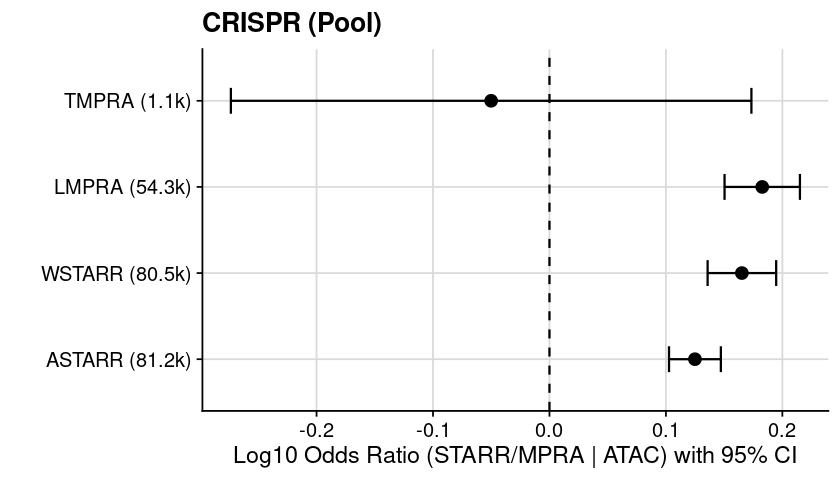

In [13]:
vec = c("STARRMPRA", VEC_TXT_ASSAY_INP)

dat = dat_logit_stats_full
dat = dat %>% 
    dplyr::mutate(Assay_STARRMPRA = factor(Assay_STARRMPRA, levels=vec)) %>%
    dplyr::mutate(Count_Label = fun_wrapper(Count)) %>%
    dplyr::mutate(Assay_Label = paste0(Assay_STARRMPRA, " (", Count_Label, ")")) %>%
    dplyr::mutate(Assay_Label = factor(Assay_Label, levels=Assay_Label))

gpt = ggplot(dat, aes(x = Log10OR, y = Assay_Label)) +
    geom_point(size = 3) +
    geom_errorbar(aes(xmin = Log10OR_CI_Lower, xmax = Log10OR_CI_Upper), width = 0.3) +
    geom_vline(xintercept = 0, linetype="dashed") +
    labs(x = "Log10 Odds Ratio (STARR/MPRA | ATAC) with 95% CI", y = "", title = "CRISPR (Pool)") +
    theme_cowplot() +
    background_grid() 

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

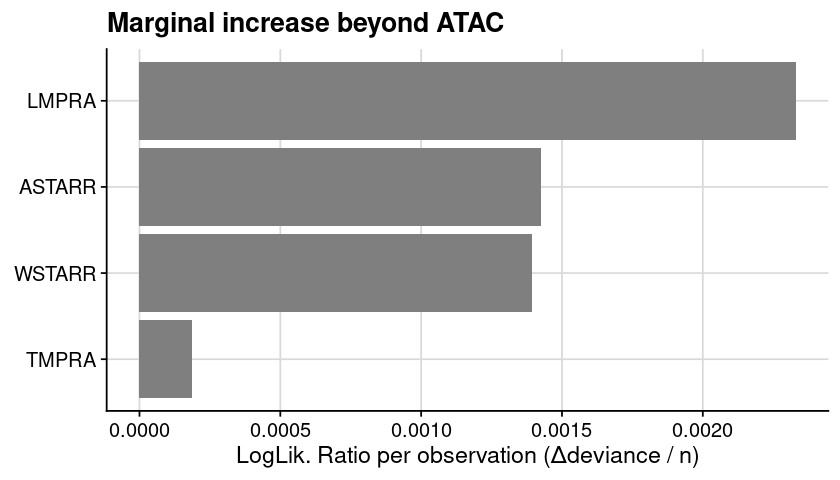

In [14]:
dat = dat_logit_stats_full
dat = dat %>% dplyr::arrange(desc(LR_per_n))

gpt = ggplot(dat, aes(y = reorder(Assay_STARRMPRA, LR_per_n), x = LR_per_n)) +
    #geom_segment(aes(x = 0, xend = LR_per_n, yend = Assay_STARRMPRA), linewidth = 2, color = "grey50") +
    #geom_point(size = 2.6) +    
    geom_col(linewidth = 2, fill = "grey50") +
    labs(
        x = "LogLik. Ratio per observation (Δdeviance / n)", 
        y = NULL,
        title = "Marginal increase beyond ATAC"
    ) +
    theme_cowplot() +
    background_grid() 

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

**Explore results from analysis 02**

In [15]:
dat = dat_logit_stats_overlap
dat = dat %>% dplyr::arrange(desc(LR_per_n))
dat = dat %>% dplyr::transmute(
    Assay_STARRMPRA, Count,
    LR_Stat, df = LR_Df,
    LR_per_n = signif(LR_per_n, 3),
    Pvalue = format(Pvalue, digits = 3, scientific = TRUE),
    `R2 (McFadden, rel)` = R2_McFadden_rel_pct
)
fun_display_table(dat)

Assay_STARRMPRA,Count,LR_Stat,df,LR_per_n,Pvalue,"R2 (McFadden, rel)"
ASTARR,802,13.3494806,1,0.01660,2.58e-04,11.34%
LMPRA,802,0.8544115,1,0.00107,3.55e-01,0.73%
WSTARR,802,0.2804483,1,0.00035,5.96e-01,0.24%
TMPRA,802,0.1439966,1,0.00018,7.04e-01,0.12%


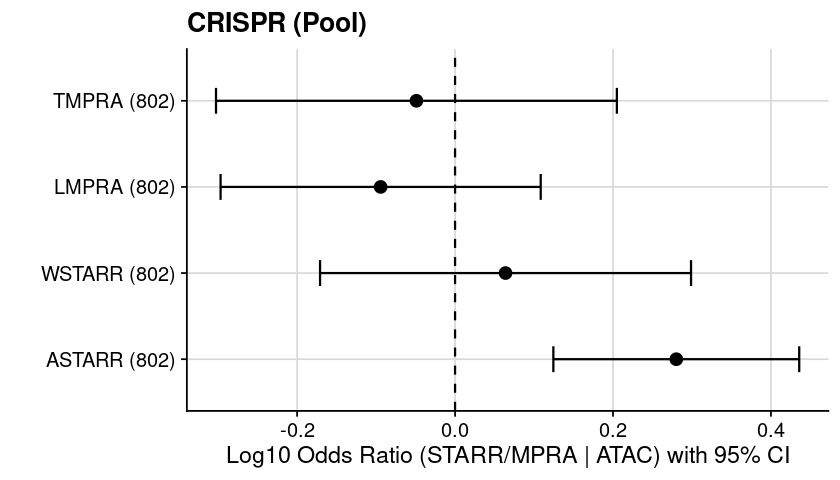

In [16]:
vec = c("STARRMPRA", VEC_TXT_ASSAY_INP)

dat = dat_logit_stats_overlap
dat = dat %>% 
    dplyr::mutate(Assay_STARRMPRA = factor(Assay_STARRMPRA, levels=vec)) %>%
    dplyr::mutate(Count_Label = fun_wrapper(Count)) %>%
    dplyr::mutate(Assay_Label = paste0(Assay_STARRMPRA, " (", Count_Label, ")")) %>%
    dplyr::mutate(Assay_Label = factor(Assay_Label, levels=Assay_Label))

gpt = ggplot(dat, aes(x = Log10OR, y = Assay_Label)) +
    geom_point(size = 3) +
    geom_errorbar(aes(xmin = Log10OR_CI_Lower, xmax = Log10OR_CI_Upper), width = 0.3) +
    geom_vline(xintercept = 0, linetype="dashed") +
    labs(x = "Log10 Odds Ratio (STARR/MPRA | ATAC) with 95% CI", y = "", title = "CRISPR (Pool)") +
    theme_cowplot() +
    background_grid() 

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

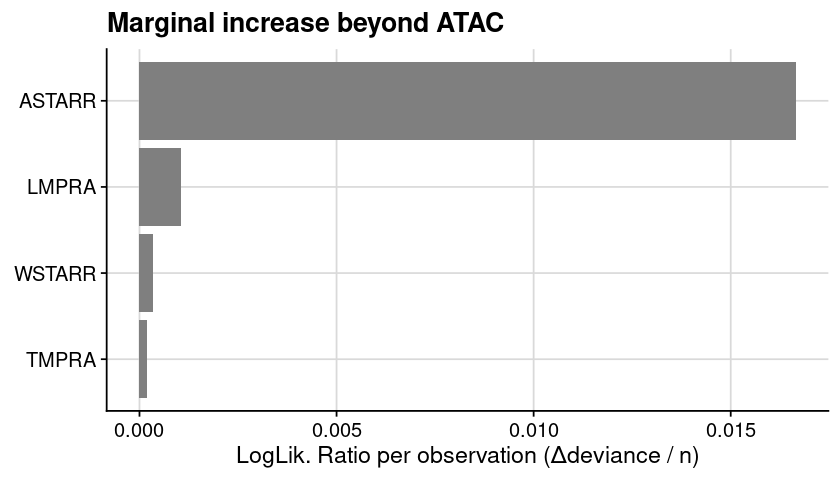

In [17]:
dat = dat_logit_stats_overlap
dat = dat %>% dplyr::arrange(desc(LR_per_n))

gpt = ggplot(dat, aes(y = reorder(Assay_STARRMPRA, LR_per_n), x = LR_per_n)) +
    #geom_segment(aes(x = 0, xend = LR_per_n, yend = Assay_STARRMPRA), linewidth = 2, color = "grey50") +
    #geom_point(size = 2.6) +    
    geom_col(linewidth = 2, fill = "grey50") +
    labs(
        x = "LogLik. Ratio per observation (Δdeviance / n)", 
        y = NULL,
        title = "Marginal increase beyond ATAC"
    ) +
    theme_cowplot() +
    background_grid() 

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

## Export results

**Export the results from analysis 01**

In [18]:
### set file directory
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "result.cripsr_vs_starrmpra.logit.stats.pool.lrtest.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### write table
dat = dat_logit_stats_full
write_tsv(dat, txt_fpath)